# Who Pays for the Cloud?
## Stress-testing Virginia household energy bills against data-center-driven rate growth — and finding where relief should go first

**DRHS DS-Team2 · 2026 Virginia Datathon (ODGA)** · Focus area: **Energy** (with Living Expenses)

**Question.** Virginia's data-center boom is pushing up generation and transmission costs for *every* ratepayer (JLARC 2024; SCC 2025 rate case). Which Virginia households can least absorb those increases, are existing Commonwealth programs (EAP, PIPP) reaching them, and where should new relief dollars go first?

**Approach.**
1. Build a household-level energy-burden baseline for all 133 localities from DOE's LEAD Tool (ACS microdata calibrated to utility billing data), updated to **2026** electricity prices (EIA).
2. **Stress-test** it with JLARC's 2040 data-center scenarios (+$14 to +$37/month per 1,000 kWh, constant dollars), applied to each household cell's actual usage — so electric-heat and inefficient homes take proportionally bigger hits.
3. Measure the **home energy affordability gap** (dollars needed to cap energy costs at 6% of income).
4. Measure program **reach**: Energy Assistance Program (EAP) households paid (VDSS, FFY2025) vs. estimated eligible households and vs. SNAP households already income-verified by the same local DSS office.
5. Classify localities into a **depth-vs-reach typology** and rank them with a **Monte Carlo–robust priority index** (100,000 draws over scenario, income, eligibility, and weighting assumptions).
6. Size a funded, implementable response against the new **Data Center Electricity Consumption Tax** (~$600M/yr).

All sources are public; most come from the 2026 Datathon collection on data.virginia.gov.

## 0. Setup & assumptions
Every tunable assumption lives in this cell, with its source.

In [1]:
import warnings; warnings.filterwarnings('ignore')
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib as mpl
from matplotlib.colors import LinearSegmentedColormap, ListedColormap
import geopandas as gpd

RAW = Path('data/raw'); FIG = Path('figures'); OUT = Path('outputs')
FIG.mkdir(exist_ok=True); OUT.mkdir(exist_ok=True)
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')

# ---- Prices & growth ---------------------------------------------------------------
P22 = 0.1334   # VA avg residential price, $/kWh, 2022 annual (EIA, data.virginia.gov "Electricity Sales")
P26 = 0.1683   # VA avg residential price, $/kWh, Jan-Jul 2026 YTD (EIA Electric Power Monthly Table 5.6.B)
INC_CAGR = (97720 / 81310) ** (1 / 5) - 1   # VA median HH income growth 2019-2024 (data.virginia.gov / FRED MEHOINUSVAA646N)
F_INC = (1 + INC_CAGR) ** 4                 # 2022 -> 2026 income factor; non-electric fuels assumed to track it
# ---- JLARC 2024 (Rpt 598, Table 4-2): Dominion typical 1,000 kWh/mo customer, gen+trans increase by 2040, 2024 $
ADD_LOW, ADD_HIGH = 14 / 1000, 37 / 1000    # $/kWh adders (half-unconstrained vs unconstrained+VCEA demand)
SCEN = {'2022 (LEAD base)': None, '2026 (actual prices)': 0.0,
        '2040 low (+$14/mo)': ADD_LOW, '2040 high (+$37/mo)': ADD_HIGH}
AFFORDABLE = 0.06   # standard affordable home energy burden threshold (6% of income)
EAP_FRAC_100_150 = 0.6   # share of 100-150% FPL households under EAP's 130% FPL limit (linear interpolation)
# ---- Program / funding facts (cited in write-up) -----------------------------------
DC_TAX = 600e6        # Data Center Electricity Consumption Tax, $0.011/kWh, ~$600M/yr cap (2026 budget, eff. 7/1/2026)
WX_COST = 8000        # avg weatherization cost per home (state WAP plans ~$6.8k-$8.5k ACPU, 2025)
# Major data-center localities named in JLARC 2024 (Ch. 1)
DC_LOCALITIES = {51107: 'Loudoun', 51153: 'Prince William', 51059: 'Fairfax', 51683: 'Manassas',
                 51087: 'Henrico', 51117: 'Mecklenburg', 51047: 'Culpeper', 51061: 'Fauquier'}
print(f'Electricity price factor 2022->2026: {P26/P22:.3f} | income factor: {F_INC:.3f}')

Electricity price factor 2022->2026: 1.262 | income factor: 1.158


In [2]:
# ---- Chart style (validated reference palette; see dataviz skill palette.md) --------
INK, INK2, MUTED, GRID, AXIS, SURF = '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7', '#fcfcfb'
BLUE, ORANGE, AQUA, GRAY = '#2a78d6', '#eb6834', '#1baf7a', '#c3c2b7'
BLUE_RAMP = ['#cde2fb', '#9ec5f4', '#6da7ec', '#3987e5', '#256abf', '#184f95', '#0d366b']
ORANGE_RAMP = ['#fde3d6', '#f8bfa3', '#f39a70', '#eb6834', '#c9501f', '#9e3d16', '#6f2a0f']
cmap_blue = LinearSegmentedColormap.from_list('blue', BLUE_RAMP)
cmap_orange = LinearSegmentedColormap.from_list('orange', ORANGE_RAMP)
mpl.rcParams.update({
    'figure.facecolor': SURF, 'axes.facecolor': SURF, 'savefig.facecolor': SURF, 'figure.dpi': 110,
    'font.family': ['Segoe UI', 'DejaVu Sans'], 'font.size': 10, 'text.color': INK,
    'axes.labelcolor': INK2, 'axes.edgecolor': AXIS, 'axes.linewidth': 0.8,
    'xtick.color': MUTED, 'ytick.color': MUTED, 'axes.grid': True, 'grid.color': GRID,
    'grid.linewidth': 0.6, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titlesize': 12, 'axes.axisbelow': True, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left', 'legend.frameon': False})
def save(fig, name):
    fig.savefig(FIG / f'{name}.png', dpi=200, bbox_inches='tight'); plt.show()

## 1. Load data
| Dataset | Source | Use |
|---|---|---|
| LEAD Tool 2022, VA counties by FPL band | DOE / OpenEI | Household counts, income, electricity/gas/other-fuel spend by tenure × building age × building type × heating fuel |
| EAP Household Counts FFY2017–2025 | VDSS via data.virginia.gov (Datathon 2026) | Households paid by locality and component |
| SNAP Participation Report, July 2026 | VDSS via data.virginia.gov (Datathon 2026) | Income-verified households by locality |
| Electricity Sales (EIA) 2010–2024 | data.virginia.gov (Datathon 2026) | Sector load growth & prices |
| EIA-861 2024 | EIA | Utility customers, service territories |
| County Typology Codes 2025 | USDA ERS via data.virginia.gov (Datathon 2026) | Metro / persistent-poverty flags |
| Cartographic boundaries 2023 | Census | Maps |

In [3]:
# --- LEAD: one row per county x FPL band x tenure x building age x building type x heating fuel ---
L = pd.read_csv(RAW / 'lead/VA FPL Counties 2022.csv').rename(columns={
    'HINCP*UNITS': 'inc_x', 'ELEP*UNITS': 'el_x', 'GASP*UNITS': 'gas_x', 'FULP*UNITS': 'ful_x',
    'HINCP UNITS': 'inc_u', 'ELEP UNITS': 'el_u', 'GASP UNITS': 'gas_u', 'FULP UNITS': 'ful_u',
    'TEN-HFL': 'hfl', 'TEN-BLD': 'bld', 'TEN-YBL6': 'ybl', 'FPL150': 'fpl'})
for c in ['hfl', 'bld', 'ybl']:
    L[c] = L[c].str.replace('^(OWNER|RENTER) ', '', regex=True)
# cell averages; impute sparse cells from county x FPL x tenure, then statewide FPL averages
for k in ['inc', 'el', 'gas', 'ful']:
    L[k] = np.where(L[k + '_u'] > 0, L[k + '_x'] / L[k + '_u'], np.nan)
    for keys in (['FIP', 'fpl', 'TEN'], ['fpl']):
        g = L.groupby(keys)
        L[k] = L[k].fillna(g[k + '_x'].transform('sum') / g[k + '_u'].transform('sum'))
L = L[L.UNITS > 0].copy()
L['kwh'] = L.el / P22                                  # implied annual kWh
L['LI'] = L.fpl.isin(['0-100%', '100-150%'])            # <=150% FPL = PIPP eligibility line
L['eap_elig'] = L.UNITS * np.select([L.fpl == '0-100%', L.fpl == '100-150%'], [1.0, EAP_FRAC_100_150], 0.0)
print(f'{len(L):,} household cells | {L.FIP.nunique()} localities | {L.UNITS.sum():,.0f} households | '
      f'{L.UNITS[L.LI].sum():,.0f} at or below 150% FPL')
L.groupby('fpl').UNITS.sum().to_frame('households')

85,441 household cells | 133 localities | 3,289,776 households | 466,049 at or below 150% FPL


,households
fpl,
0-100%,"273,470.555"
100-150%,"192,578.102"
150-200%,"208,779.619"
200-400%,"817,703.610"
400%+,"1,797,243.915"


In [4]:
# --- EAP households paid, by locality / FFY / component (FU=fuel/heating, CO=cooling, CR=crisis) ---
eap = pd.read_excel(RAW / 'eap_counts.xlsx', sheet_name='By FIPS', dtype={'FIPS_txt': str})
eap['FIP'] = 51000 + eap.FIPS_txt.astype(int)
for c in ['HH < 100% POVERTY', 'TOTAL # OF HH PAID', 'TOTAL $ AMOUNT PAID']:
    eap[c] = pd.to_numeric(eap[c], errors='coerce')        # suppressed small cells -> NaN
eap_hh = eap.pivot_table(index='FIP', columns=['FFY', 'Component'], values='TOTAL # OF HH PAID', aggfunc='sum')
eap_state = eap.groupby(['FFY', 'Component'])[['TOTAL # OF HH PAID', 'TOTAL $ AMOUNT PAID']].sum().unstack()
print('Statewide EAP households paid (FU = heating):')
display(eap_state['TOTAL # OF HH PAID'].astype(int).T)
print(f"FFY2025 EAP dollars paid, all components: ${eap_state.loc[2025, 'TOTAL $ AMOUNT PAID'].sum()/1e6:,.1f}M")

# --- SNAP households, July 2026 ---
snap = pd.read_excel(RAW / 'snap_july_2026.xls', header=3, dtype={'FIPS': str})
snap = snap[snap.FIPS.notna()].assign(FIP=lambda d: 51000 + d.FIPS.astype(int))
snap = snap.set_index('FIP')['HOUSEHOLDS\n (TOTAL)'].astype(float).rename('snap_hh')
print(f'SNAP households (Jul 2026): {snap.sum():,.0f} across {len(snap)} localities')

# --- ERS typology (metro flag, persistent poverty) ---
ers = pd.read_csv(RAW / 'ers_typology_2025.csv', dtype=str, encoding='latin1').query("State == 'VA'")
ers['FIP'] = ers.FIPStxt.astype(int)
ersw = ers.pivot_table(index='FIP', columns='Attribute', values='Value', aggfunc='first').astype(float)
ersw['metro'] = ers.drop_duplicates('FIP').set_index('FIP').Metro2023.astype(int)

# --- Utility territories (EIA-861 2024) ---
terr = pd.read_excel(RAW / 'eia861/Service_Territory_2024.xlsx', sheet_name='Counties_States').query("State == 'VA'")
n_dom = terr.loc[terr['Utility Name'].eq('Virginia Electric & Power Co'), 'County'].nunique()
print(f'Dominion (Virginia Electric & Power) serves part or all of {n_dom} of {terr.County.nunique()} VA county/city territories')

# --- Geometry ---
geo = gpd.read_file('zip://' + str(RAW / 'cb_2023_us_county_5m.zip')).query("STATEFP == '51'")
geo['FIP'] = geo.GEOID.astype(int)
geo = geo.to_crs(3968)   # Virginia Lambert
print(len(geo), 'locality polygons')

Statewide EAP households paid (FU = heating):


FFY,2017,2018,2019,2020,2021,2022,2023,2024,2025
Component,,,,,,,,,
CO,65481,66784,66120,67430,68141,83088,84822,84752,79616
CR,15265,18121,16679,15079,13091,22354,17022,14279,12210
FU,111855,109786,107322,104448,102174,106283,113584,117286,107549


FFY2025 EAP dollars paid, all components: $82.2M
SNAP households (Jul 2026): 384,483 across 132 localities


Dominion (Virginia Electric & Power) serves part or all of 104 of 134 VA county/city territories
133 locality polygons


## 2. Context — the load is coming from data centers, the bill goes to everyone
Virginia's commercial-sector electricity sales (where data centers are metered) grew ~60% since 2016 while residential use was flat. Indexed to a common base so both sit on one axis.

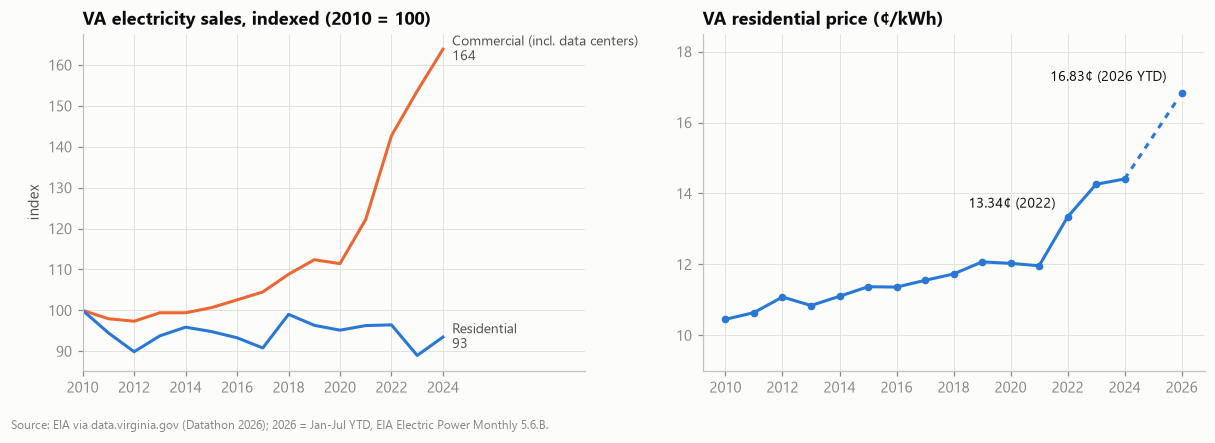

Commercial sales growth 2016->2024: +60%; residential price 2022->2026: +26%


In [5]:
es = pd.read_excel(RAW / 'eia_sales_provider.xlsx', sheet_name='Total Electric Industry', header=None)
es = es.iloc[3:, [0, 1, 3, 5, 7]]; es.columns = ['year', 'state', 'res_mwh', 'res_price', 'com_mwh']
es = es[es.state == 'VA'].astype({'year': int, 'res_mwh': float, 'res_price': float, 'com_mwh': float}).sort_values('year')
base = es.iloc[0]
es['Residential'] = es.res_mwh / base.res_mwh * 100; es['Commercial (incl. data centers)'] = es.com_mwh / base.com_mwh * 100

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
ax = axes[0]
for col, c in [('Commercial (incl. data centers)', ORANGE), ('Residential', BLUE)]:
    ax.plot(es.year, es[col], color=c, lw=2)
    ax.annotate(f"{col}\n{es[col].iloc[-1]:.0f}", (es.year.iloc[-1], es[col].iloc[-1]), xytext=(6, 0),
                textcoords='offset points', va='center', fontsize=9, color=INK2)
ax.set_title('VA electricity sales, indexed (2010 = 100)'); ax.set_xlim(2010, 2029.5); ax.set_ylabel('index')
ax.set_xticks(range(2010, 2025, 2))
ax = axes[1]
pr = pd.concat([es.set_index('year').res_price, pd.Series({2026: P26 * 100})])
ax.plot(pr.index[:-1], pr.values[:-1], color=BLUE, lw=2, marker='o', ms=4)
ax.plot(pr.index[-2:], pr.values[-2:], color=BLUE, lw=2, ls=(0, (2, 2)))
ax.scatter([2026], [P26 * 100], s=50, color=BLUE, zorder=3, edgecolor=SURF, linewidth=2)
ax.annotate(f'{P26*100:.2f}¢ (2026 YTD)', (2026, P26 * 100), xytext=(-10, 8), textcoords='offset points', ha='right', fontsize=9)
ax.annotate(f'{P22*100:.2f}¢ (2022)', (2022, P22 * 100), xytext=(-8, 6), textcoords='offset points', ha='right', fontsize=9)
ax.set_title('VA residential price (¢/kWh)'); ax.set_ylim(9, 18.5)
fig.text(0, -0.04, 'Source: EIA via data.virginia.gov (Datathon 2026); 2026 = Jan-Jul YTD, EIA Electric Power Monthly 5.6.B.',
         fontsize=8, color=MUTED)
plt.tight_layout(); save(fig, '01_context_load_and_price')
growth_com = es.com_mwh.iloc[-1] / es.loc[es.year == 2016, 'com_mwh'].iloc[0] - 1
print(f'Commercial sales growth 2016->2024: {growth_com:+.0%}; residential price 2022->2026: {P26/P22-1:+.0%}')

## 3. 2026 baseline: who carries the energy burden?
Energy burden = household energy spending ÷ household income. Aggregates use LEAD's convention (total cost ÷ total income). For counts of households above a threshold we use cell-average burden (each LEAD cell is a group of near-identical households).

In [6]:
def scenario_costs(adder, frame=L):
    # Returns (annual energy cost, annual income) per household cell for a scenario.
    if adder is None:
        return frame.el + frame.gas + frame.ful, frame.inc
    return frame.kwh * (P26 + adder) + (frame.gas + frame.ful) * F_INC, frame.inc * F_INC

L['c26'], L['i26'] = scenario_costs(0.0)
L['b26'] = np.where(L.i26 > 0, L.c26 / L.i26, np.inf)

def agg_burden(g, c='c26', i='i26'):
    return pd.Series({'households': g.UNITS.sum(),
                      'avg_energy_cost': (g[c] * g.UNITS).sum() / g.UNITS.sum(),
                      'avg_income': (g[i] * g.UNITS).sum() / g.UNITS.sum(),
                      'energy_burden': (g[c] * g.UNITS).sum() / (g[i].clip(lower=0) * g.UNITS).sum()})

by_fpl = L.groupby('fpl').apply(agg_burden).loc[['0-100%', '100-150%', '150-200%', '200-400%', '400%+']]
display(by_fpl)
li = L[L.LI]
by_fuel = li.groupby('hfl').apply(agg_burden).sort_values('households', ascending=False)
by_bld = li.assign(bld2=li.bld.where(li.bld.isin(['1 DETACHED', 'MOBILE_TRAILER', '1 ATTACHED']), 'Multifamily (2+ units)')) \
           .groupby('bld2').apply(agg_burden)
display(by_fuel.head(6)); display(by_bld)

,households,avg_energy_cost,avg_income,energy_burden
fpl,,,,
0-100%,"273,470.555","2,670.595","11,667.965",0.229
100-150%,"192,578.102","2,720.428","29,029.612",0.094
150-200%,"208,779.619","2,812.720","42,799.056",0.066
200-400%,"817,703.610","2,894.513","74,166.367",0.039
400%+,"1,797,243.915","3,107.783","211,338.722",0.015


,households,avg_energy_cost,avg_income,energy_burden
hfl,,,,
ELECTRICITY,"312,263.395","2,391.601","18,717.581",0.128
UTILITY GAS,"92,520.785","2,860.859","19,569.086",0.146
FUEL OIL,"24,644.230","4,729.433","17,915.389",0.264
BOTTLED GAS,"18,298.826","3,983.075","18,945.196",0.210
WOOD,"11,801.077","3,204.522","19,986.641",0.160
NONE,"4,359.018","2,208.989","15,128.154",0.146


,households,avg_energy_cost,avg_income,energy_burden
bld2,,,,
1 ATTACHED,"37,129.197","2,398.879","21,496.545",0.112
1 DETACHED,"214,754.272","3,419.692","20,310.174",0.168
MOBILE_TRAILER,"42,542.437","2,903.153","19,487.582",0.149
Multifamily (2+ units),"171,622.751","1,790.293","16,270.670",0.110


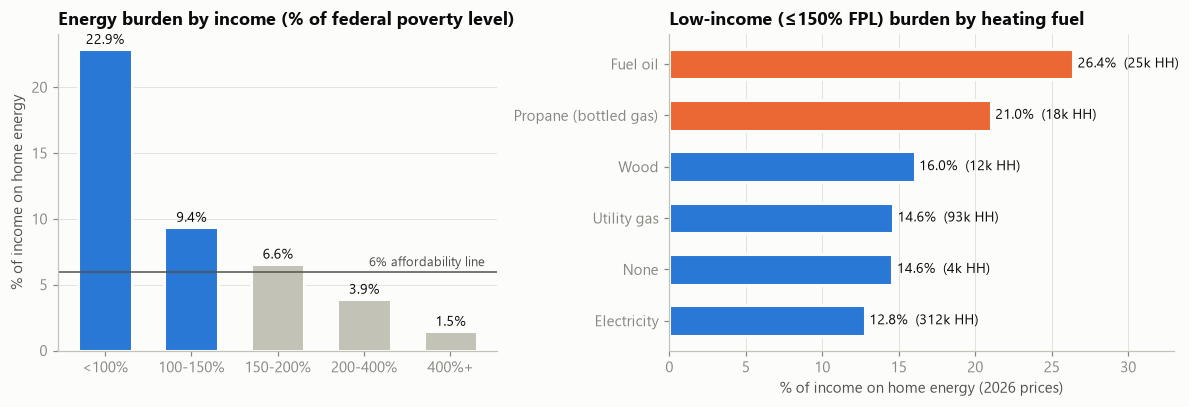

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={'width_ratios': [1, 1.15]})
ax = axes[0]
labels = ['<100%', '100-150%', '150-200%', '200-400%', '400%+']
vals = by_fpl.energy_burden.values * 100
bars = ax.bar(labels, vals, color=[BLUE if i < 2 else GRAY for i in range(5)], width=0.62, edgecolor=SURF, linewidth=2)
ax.axhline(6, color=INK2, lw=1); ax.text(4.4, 6.4, '6% affordability line', ha='right', fontsize=8.5, color=INK2)
for b, v in zip(bars, vals):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.4, f'{v:.1f}%', ha='center', fontsize=9, color=INK)
ax.set_title('Energy burden by income (% of federal poverty level)'); ax.set_ylabel('% of income on home energy')
ax.grid(axis='x', visible=False)
ax = axes[1]
f = by_fuel[by_fuel.households > 4000].sort_values('energy_burden')
names = {'ELECTRICITY': 'Electricity', 'UTILITY GAS': 'Utility gas', 'FUEL OIL': 'Fuel oil', 'BOTTLED GAS': 'Propane (bottled gas)',
         'WOOD': 'Wood', 'NONE': 'None'}
ax.barh([names.get(i, i) for i in f.index], f.energy_burden * 100,
        color=[ORANGE if i in ('FUEL OIL', 'BOTTLED GAS') else BLUE for i in f.index], height=0.6, edgecolor=SURF, linewidth=2)
for y, (v, n) in enumerate(zip(f.energy_burden * 100, f.households)):
    ax.text(v + 0.3, y, f'{v:.1f}%  ({n/1000:,.0f}k HH)', va='center', fontsize=9)
ax.set_title('Low-income (≤150% FPL) burden by heating fuel'); ax.set_xlim(0, 33); ax.grid(axis='y', visible=False)
ax.set_xlabel('% of income on home energy (2026 prices)')
plt.tight_layout(); save(fig, '02_burden_by_income_and_fuel')

## 4. Stress test: 2026 → 2040 data-center scenarios
JLARC's adders are applied **per kWh** to every household cell (not as a flat dollar amount), so homes that use more electricity — electric resistance heat, mobile homes, poor insulation — absorb more. Incomes are held at 2026 levels (JLARC figures are in constant dollars).

**Affordability gap** = Σ max(0, energy cost − 6% × income) over households at or below 150% FPL — the annual dollars it would take to bring every low-income Virginia household down to an affordable burden.

In [8]:
rows = []
for name, a in SCEN.items():
    c, i = scenario_costs(a)
    b = np.where(i > 0, c / i, np.inf)
    gap = np.maximum(0, c - AFFORDABLE * i.clip(lower=0)) * L.UNITS
    m = L.LI
    rows.append({'scenario': name,
                 'LI avg burden': (c[m] * L.UNITS[m]).sum() / (i[m].clip(lower=0) * L.UNITS[m]).sum(),
                 'All-HH avg burden': (c * L.UNITS).sum() / (i.clip(lower=0) * L.UNITS).sum(),
                 'LI avg annual cost': (c[m] * L.UNITS[m]).sum() / L.UNITS[m].sum(),
                 'LI HH >6%': L.UNITS[m & (b > .06)].sum(), 'LI HH >10%': L.UNITS[m & (b > .10)].sum(),
                 'All HH >6%': L.UNITS[b > .06].sum(), 'LI affordability gap ($M/yr)': gap[m].sum() / 1e6})
    L['gap_' + name] = gap
STRESS = pd.DataFrame(rows).set_index('scenario')
display(STRESS.style.format({'LI avg burden': '{:.1%}', 'All-HH avg burden': '{:.1%}', 'LI avg annual cost': '${:,.0f}',
                             'LI HH >6%': '{:,.0f}', 'LI HH >10%': '{:,.0f}', 'All HH >6%': '{:,.0f}',
                             'LI affordability gap ($M/yr)': '${:,.0f}M'}))
eap25 = eap_state.loc[2025, 'TOTAL $ AMOUNT PAID'].sum() / 1e6
gap26 = STRESS.loc['2026 (actual prices)', 'LI affordability gap ($M/yr)']
gap40h = STRESS.loc['2040 high (+$37/mo)', 'LI affordability gap ($M/yr)']
gap40l = STRESS.loc['2040 low (+$14/mo)', 'LI affordability gap ($M/yr)']
print(f'EAP covers {eap25/gap26:.0%} of the 2026 gap (${eap25:,.0f}M of ${gap26:,.0f}M).')
print(f'Data-center scenarios add ${gap40l-gap26:,.0f}M-${gap40h-gap26:,.0f}M/yr to the gap '
      f'= {(gap40l-gap26)/(DC_TAX/1e6):.0%}-{(gap40h-gap26)/(DC_TAX/1e6):.0%} of the ~$600M/yr data-center electricity tax.')

,LI avg burden,All-HH avg burden,LI avg annual cost,LI HH >6%,LI HH >10%,All HH >6%,LI affordability gap ($M/yr)
scenario,,,,,,,
2022 (LEAD base),13.4%,2.0%,"$2,176","406,121","295,027","566,319",$583M
2026 (actual prices),14.3%,2.1%,"$2,691","417,237","314,224","608,146",$749M
2040 low (+$14/mo),15.2%,2.3%,"$2,865","425,533","331,241","641,843",$826M
2040 high (+$37/mo),16.7%,2.5%,"$3,150","437,565","358,430","704,746",$955M


EAP covers 11% of the 2026 gap ($82M of $749M).
Data-center scenarios add $77M-$205M/yr to the gap = 13%-34% of the ~$600M/yr data-center electricity tax.


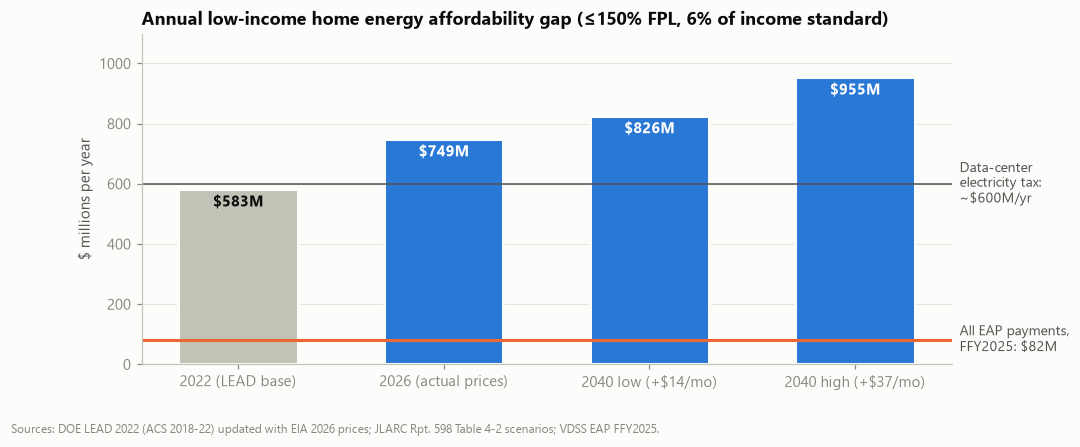

In [9]:
fig, ax = plt.subplots(figsize=(9.5, 3.9))
order = list(SCEN.keys())
v = STRESS['LI affordability gap ($M/yr)'].values
bars = ax.bar(range(4), v, color=[GRAY, BLUE, BLUE, BLUE], width=0.58, edgecolor=SURF, linewidth=2)
for k, b in enumerate(bars):
    ax.text(b.get_x() + b.get_width() / 2, v[k] - 18, f'${v[k]:,.0f}M', ha='center', va='top', fontsize=10,
            fontweight='bold', color=INK if k == 0 else 'white')
tr = mpl.transforms.blended_transform_factory(ax.transAxes, ax.transData)
ax.axhline(eap25, color=ORANGE, lw=2)
ax.text(1.01, eap25, f'All EAP payments,\nFFY2025: ${eap25:,.0f}M', transform=tr, va='center', color=INK2, fontsize=9)
ax.axhline(DC_TAX / 1e6, color=INK2, lw=1)
ax.text(1.01, DC_TAX / 1e6, 'Data-center\nelectricity tax:\n~$600M/yr', transform=tr, va='center', color=INK2, fontsize=9)
ax.set_xticks(range(4), order); ax.set_ylabel('$ millions per year'); ax.grid(axis='x', visible=False)
ax.set_title('Annual low-income home energy affordability gap (≤150% FPL, 6% of income standard)')
ax.set_ylim(0, max(v) * 1.15)
fig.text(0, -0.05, 'Sources: DOE LEAD 2022 (ACS 2018-22) updated with EIA 2026 prices; JLARC Rpt. 598 Table 4-2 scenarios; VDSS EAP FFY2025.',
         fontsize=8, color=MUTED)
save(fig, '03_affordability_gap_scenarios')

## 5. Locality view: depth of need vs. reach of existing programs
* **EAP reach** = EAP heating (fuel) households paid in FFY2025 ÷ estimated EAP-eligible households (≤130% FPL, from LEAD).
* **SNAP cross-enrollment** = EAP heating households ÷ SNAP households (July 2026). SNAP households are already income-verified by the *same* local DSS office that runs EAP — an assumption-light check on reach.

In [10]:
L['c40h'], _ = scenario_costs(ADD_HIGH)
li = L[L.LI]
grp = li.groupby('FIP')
C = pd.DataFrame({
    'name': L.groupby('FIP').NAME.first(),
    'households': L.groupby('FIP').UNITS.sum(),
    'li_hh': grp.UNITS.sum(),
    'eap_elig': L.groupby('FIP').eap_elig.sum(),
    'li_burden26': grp.apply(lambda g: (g.c26 * g.UNITS).sum() / (g.i26.clip(lower=0) * g.UNITS).sum()),
    'li_burden40h': grp.apply(lambda g: (g.c40h * g.UNITS).sum() / (g.i26.clip(lower=0) * g.UNITS).sum()),
    'gap26': grp['gap_2026 (actual prices)'].sum(),
    'gap40h': grp['gap_2040 high (+$37/mo)'].sum(),
    'li_over10': li[li.b26 > .10].groupby('FIP').UNITS.sum(),
    'li_oil_propane': li[li.hfl.isin(['FUEL OIL', 'BOTTLED GAS'])].groupby('FIP').UNITS.sum(),
    'li_elec_heat': li[li.hfl == 'ELECTRICITY'].groupby('FIP').UNITS.sum(),
    'li_mobile': li[li.bld == 'MOBILE_TRAILER'].groupby('FIP').UNITS.sum(),
    'li_owner': li[li.TEN == 'OWN'].groupby('FIP').UNITS.sum(),
}).fillna({'li_over10': 0, 'li_oil_propane': 0, 'li_elec_heat': 0, 'li_mobile': 0, 'li_owner': 0})
C['li_share'] = C.li_hh / C.households
C['gap_per_li'] = C.gap26 / C.li_hh
C['dc_cost_per_li'] = grp.apply(lambda g: ((g.c40h - g.c26) * g.UNITS).sum() / g.UNITS.sum())
# Some localities are reported under a combined local DSS agency (e.g., Salem within Roanoke County):
# compute program counts at the agency level, then allocate back in proportion to eligible households.
lk = pd.read_excel(RAW / 'eap_counts.xlsx', sheet_name='Lookup', dtype=str).dropna(subset=['FIPS'])
lk = lk[lk.FIPS.str.isdigit()]
comb = dict(zip(51000 + lk.FIPS.astype(int), 51000 + lk['Combined FIPS'].astype(int)))
C['agency'] = [f if f in eap_hh.index and f in snap.index else comb.get(f, f) for f in C.index]
ag_elig = C.groupby('agency').eap_elig.transform('sum')
ag_li = C.groupby('agency').li_hh.transform('sum')
C['eap_hh25'] = C.agency.map(eap_hh[(2025, 'FU')]) * C.eap_elig / ag_elig
C['snap_hh'] = C.agency.map(snap) * C.li_hh / ag_li
print('Localities reported under a combined agency:', C.loc[C.agency != C.index, 'name'].tolist())
C['eap_reach'] = C.eap_hh25 / C.eap_elig
C['snap_xenroll'] = C.eap_hh25 / C.snap_hh
C['snap_not_in_eap'] = (C.snap_hh - C.eap_hh25).clip(lower=0)
C = C.join(ersw[['metro', 'Persistent_Poverty_1721']].rename(columns={'Persistent_Poverty_1721': 'persistent_poverty'}))
C['dc_market'] = C.index.isin(DC_LOCALITIES)
for c in ['li_oil_propane', 'li_elec_heat', 'li_mobile', 'li_over10']:
    C[c + '_pct'] = C[c] / C.li_hh
print('Missing EAP rows:', C[C.eap_hh25.isna()].name.tolist(), '| missing SNAP rows:', C[C.snap_hh.isna()].name.tolist())
print(f"Statewide EAP reach: {C.eap_hh25.sum()/C.eap_elig.sum():.1%} of est. eligible | "
      f"SNAP cross-enrollment: {C.eap_hh25.sum()/C.snap_hh.sum():.1%} | SNAP HH not receiving EAP: {C.snap_not_in_eap.sum():,.0f}")
print('Rank correlation, FPL-based reach vs SNAP cross-enrollment:', round(C[['eap_reach', 'snap_xenroll']].corr('spearman').iloc[0, 1], 2))

Localities reported under a combined agency: ['Salem city']
Missing EAP rows: [] | missing SNAP rows: []
Statewide EAP reach: 27.6% of est. eligible | SNAP cross-enrollment: 28.0% | SNAP HH not receiving EAP: 276,934
Rank correlation, FPL-based reach vs SNAP cross-enrollment: 0.86


In [11]:
def grp_summary(g):
    return pd.Series({'localities': len(g), 'LI households': g.li_hh.sum(),
                      'median LI burden 2026': g.li_burden26.median(),
                      'gap per LI HH ($/yr)': g.gap26.sum() / g.li_hh.sum(),
                      'added cost per LI HH, 2040 high ($/yr)': (g.dc_cost_per_li * g.li_hh).sum() / g.li_hh.sum(),
                      'EAP reach': g.eap_hh25.sum() / g.eap_elig.sum(),
                      'SNAP cross-enroll': g.eap_hh25.sum() / g.snap_hh.sum(),
                      '% LI oil/propane heat': g.li_oil_propane.sum() / g.li_hh.sum(),
                      '% LI mobile homes': g.li_mobile.sum() / g.li_hh.sum()})
cmp = pd.concat({'Rural (nonmetro)': grp_summary(C[C.metro == 0]), 'Metro': grp_summary(C[C.metro == 1]),
                 'Data-center markets': grp_summary(C[C.dc_market]), 'Statewide': grp_summary(C)}, axis=1)
display(cmp.style.format(lambda x: f'{x:.1%}' if abs(x) < 1 else f'{x:,.0f}'))

,Rural (nonmetro),Metro,Data-center markets,Statewide
localities,53,80,8,133
LI households,"103,845","362,203","74,950","466,049"
median LI burden 2026,16.3%,14.2%,13.0%,15.5%
gap per LI HH ($/yr),"1,947","1,510","1,360","1,608"
"added cost per LI HH, 2040 high ($/yr)",498,448,422,459
EAP reach,49.1%,21.6%,13.6%,27.6%
SNAP cross-enroll,48.5%,22.0%,12.9%,28.0%
% LI oil/propane heat,19.0%,6.4%,6.5%,9.2%
% LI mobile homes,21.3%,5.6%,2.8%,9.1%


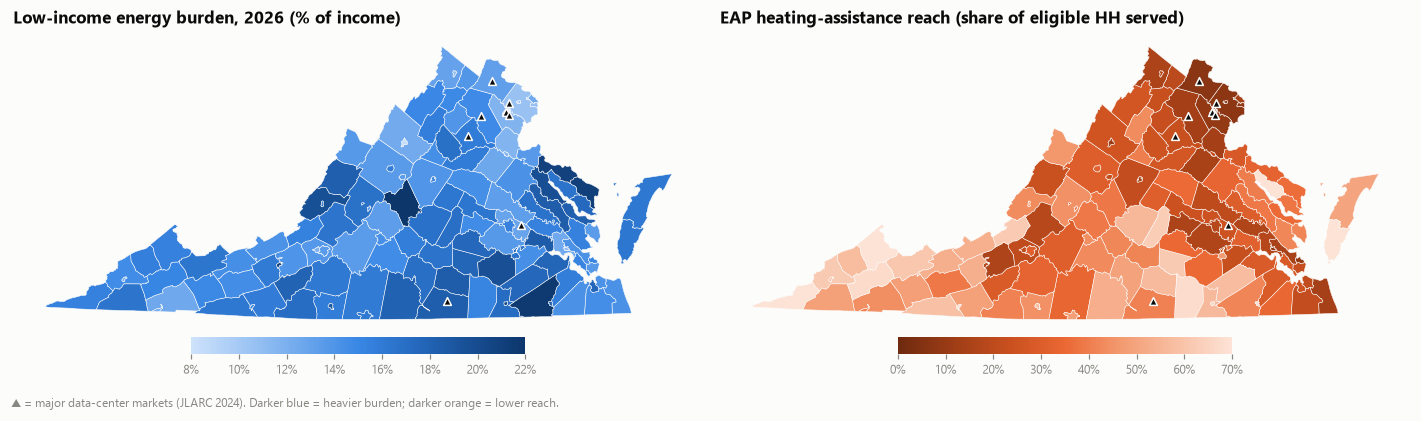

In [12]:
G = geo.merge(C.reset_index(), on='FIP', how='left')
def vmap(ax, col, cmap, title, fmt, vmin=None, vmax=None, k=6):
    G.plot(column=col, cmap=cmap, ax=ax, edgecolor=SURF, linewidth=0.35, vmin=vmin, vmax=vmax,
           missing_kwds={'color': '#eeeeea'})
    ax.set_axis_off(); ax.set_title(title, fontsize=11)
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin if vmin is not None else G[col].min(),
                                                            vmax if vmax is not None else G[col].max()))
    cb = plt.colorbar(sm, ax=ax, orientation='horizontal', fraction=0.04, pad=0.01, format=fmt)
    cb.outline.set_visible(False); cb.ax.tick_params(labelsize=8, colors=MUTED)
def mark_dc(ax):
    pts = G[G.FIP.isin(DC_LOCALITIES)].representative_point()
    ax.scatter(pts.x, pts.y, marker='^', s=26, color=INK, edgecolor=SURF, linewidth=1, zorder=4, label='Data-center market')
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
vmap(axes[0], 'li_burden26', cmap_blue, 'Low-income energy burden, 2026 (% of income)',
     mpl.ticker.PercentFormatter(1, 0), 0.08, 0.22)
vmap(axes[1], 'eap_reach', cmap_orange.reversed(), 'EAP heating-assistance reach (share of eligible HH served)',
     mpl.ticker.PercentFormatter(1, 0), 0.0, 0.7)
for ax in axes: mark_dc(ax)
fig.text(0.01, -0.03, '▲ = major data-center markets (JLARC 2024). Darker blue = heavier burden; darker orange = lower reach.',
         fontsize=8, color=MUTED)
plt.tight_layout(); save(fig, '04_maps_burden_and_reach')

## 6. Typology: "depth" problems vs. "reach" problems
Localities split on two axes (statewide medians): **affordability gap per low-income household** (depth) and **EAP reach**. Each quadrant needs a different fix — which is the core of our recommendation.

,localities,li_hh,gap_M,snap_not_in_eap,oil_propane_mobile,recommended fix
typology,,,,,,
Depth gap,44,"77,837.104",160.693,"35,704.000","17,261.127","weatherization, heat pumps (HB2), larger benefits"
Double gap,23,"37,220.050",76.290,"23,638.000","4,480.197",auto-enroll + weatherize/heat pumps
Lower priority,23,"65,538.757",106.780,"32,389.000","6,111.957",monitor annually
Reach gap,43,"285,452.746",405.486,"185,203.000","15,089.776","SNAP→EAP/PIPP auto-enrollment, outreach"


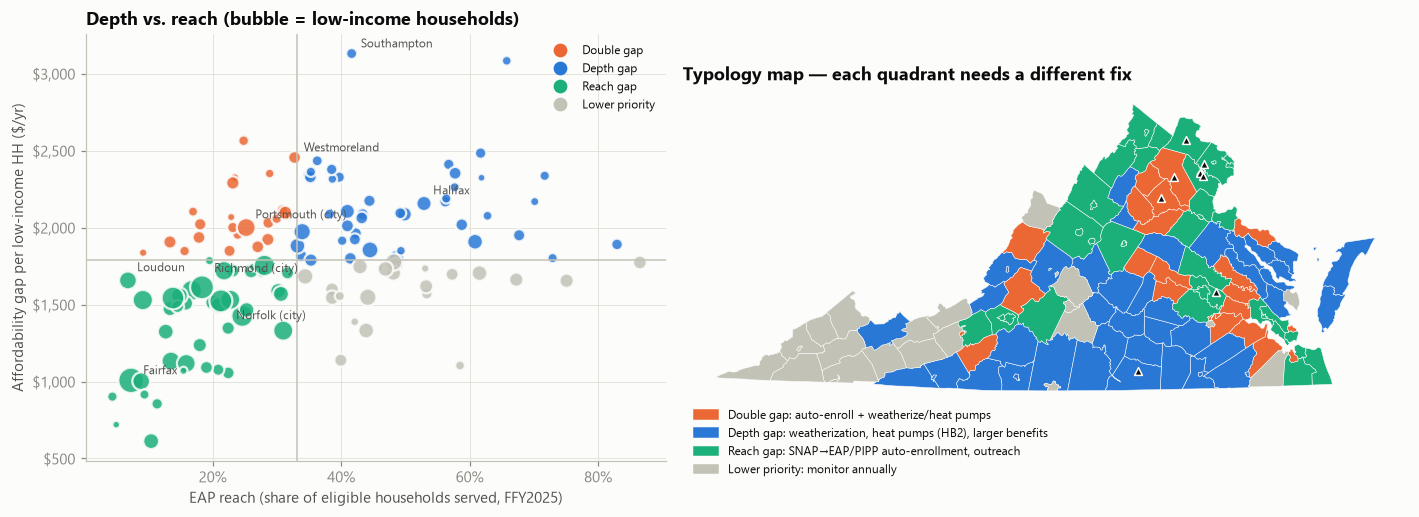

In [13]:
gx, gy = C.eap_reach.median(), C.gap_per_li.median()
def quad(r):
    if pd.isna(r.eap_reach): return 'Insufficient data'
    hi_gap, lo_reach = r.gap_per_li >= gy, r.eap_reach < gx
    return {(True, True): 'Double gap', (True, False): 'Depth gap', (False, True): 'Reach gap', (False, False): 'Lower priority'}[(hi_gap, lo_reach)]
C['typology'] = C.apply(quad, axis=1)
QCOL = {'Double gap': ORANGE, 'Depth gap': BLUE, 'Reach gap': AQUA, 'Lower priority': GRAY, 'Insufficient data': '#eeeeea'}
QFIX = {'Double gap': 'auto-enroll + weatherize/heat pumps', 'Depth gap': 'weatherization, heat pumps (HB2), larger benefits',
        'Reach gap': 'SNAP→EAP/PIPP auto-enrollment, outreach', 'Lower priority': 'monitor annually'}
tq = C.groupby('typology').agg(localities=('name', 'size'), li_hh=('li_hh', 'sum'), gap_M=('gap26', lambda s: s.sum() / 1e6),
                               snap_not_in_eap=('snap_not_in_eap', 'sum'), oil_propane_mobile=('li_oil_propane', 'sum'))
tq['recommended fix'] = tq.index.map(QFIX); display(tq)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={'width_ratios': [1, 1.25]})
ax = axes[0]
for q, d in C.groupby('typology'):
    if q == 'Insufficient data': continue
    ax.scatter(d.eap_reach, d.gap_per_li, s=np.sqrt(d.li_hh) * 1.6, color=QCOL[q], alpha=0.85, edgecolor=SURF, linewidth=1.5, label=q)
ax.axvline(gx, color=AXIS, lw=1); ax.axhline(gy, color=AXIS, lw=1)
LBL = {51760: (8, 10), 51059: (8, 4), 51107: (6, 6), 51175: (6, 4), 51083: (6, 6), 51710: (10, -12), 51740: (6, 6), 51193: (6, 4)}
for fip, off in LBL.items():
    r = C.loc[fip]; ax.annotate(r['name'].replace(' County', '').replace(' city', ' (city)'), (r.eap_reach, r.gap_per_li),
                                xytext=off, textcoords='offset points', fontsize=8, color=INK2)
ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1, 0)); ax.yaxis.set_major_formatter(mpl.ticker.StrMethodFormatter('${x:,.0f}'))
ax.set_xlabel('EAP reach (share of eligible households served, FFY2025)'); ax.set_ylabel('Affordability gap per low-income HH ($/yr)')
ax.set_title('Depth vs. reach (bubble = low-income households)')
from matplotlib.lines import Line2D
ax.legend(handles=[Line2D([], [], marker='o', ls='', ms=8, color=QCOL[q], label=q) for q in QFIX], fontsize=8, loc='upper right')
ax = axes[1]
G = geo.merge(C.reset_index(), on='FIP', how='left')
G.plot(color=G.typology.map(QCOL).fillna('#eeeeea'), ax=ax, edgecolor=SURF, linewidth=0.35)
mark_dc(ax); ax.set_axis_off(); ax.set_title('Typology map — each quadrant needs a different fix')
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=QCOL[q], label=f'{q}: {QFIX[q]}') for q in QFIX], loc='upper left', bbox_to_anchor=(0, 0.02), fontsize=8, ncol=1)
plt.tight_layout(); save(fig, '05_typology')

## 7. Priority index with Monte Carlo robustness
A single weighted index invites the question "why those weights?" — so we don't pick one. Each of **100,000 draws** samples:
* data-center scenario adder ~ U(+1.4¢, +3.7¢/kWh) (JLARC range)
* 2022→2026 income growth factor ~ U(1.10, 1.20)
* share of 100–150% FPL households under EAP's 130% limit ~ U(0.5, 0.7)
* weights over four components ~ Dirichlet(5,5,5,5) (each weight typically 10%–45%, centered on equal weighting): **severity** (low-income burden), **depth** (gap per LI household), **scale** (total gap $), **reach gap** (1 − EAP reach)

Each locality's score is the weighted average of its percentile ranks; we record how often it lands in the top 20. Localities that are top-20 in ≥ 80% of draws are **robust priorities**; ≥ 50% are **likely priorities**.

In [14]:
rng = np.random.default_rng(2026)
N = 100_000
fips = C.index[C.eap_hh25.notna()]
A_GRID = np.round(np.arange(ADD_LOW, ADD_HIGH + 1e-9, 0.001), 4)
F_GRID = np.round(np.arange(1.10, 1.2001, 0.02), 2)
# Precompute county-level burden & gap on the (adder, income-factor) grid from household cells
lic = L[L.LI & L.FIP.isin(fips)]
pos = pd.Index(fips).get_indexer(lic.FIP)
nf = len(fips)
BUR = np.zeros((len(A_GRID), len(F_GRID), nf)); GAP = np.zeros_like(BUR)
inc0, kwh, oth, u = lic.inc.values, lic.kwh.values, (lic.gas + lic.ful).values, lic.UNITS.values
for i, a in enumerate(A_GRID):
    for j, f in enumerate(F_GRID):
        c = kwh * (P26 + a) + oth * f; inc = np.clip(inc0 * f, 0, None)
        BUR[i, j] = np.bincount(pos, c * u, nf) / np.bincount(pos, inc * u, nf)
        GAP[i, j] = np.bincount(pos, np.maximum(0, c - AFFORDABLE * inc) * u, nf)
li_hh = C.loc[fips, 'li_hh'].values
u0 = L[L.fpl.eq('0-100%')].groupby('FIP').UNITS.sum().reindex(fips).values
u1 = L[L.fpl.eq('100-150%')].groupby('FIP').UNITS.sum().reindex(fips).values
eap_n = C.loc[fips, 'eap_hh25'].values

def pct_rank(x):  # rows = draws
    return (np.argsort(np.argsort(x, axis=1), axis=1) + 0.5) / x.shape[1]
ai = rng.integers(0, len(A_GRID), N); fj = rng.integers(0, len(F_GRID), N)
q = rng.uniform(0.5, 0.7, N); W = rng.dirichlet(np.full(4, 5.0), N)
sev, gap = BUR[ai, fj], GAP[ai, fj]
reach = eap_n / (u0 + q[:, None] * u1)
comps = np.stack([pct_rank(sev), pct_rank(gap / li_hh), pct_rank(gap), pct_rank(-reach)], axis=-1)
score = (comps * W[:, None, :]).sum(-1)
rank = np.argsort(np.argsort(-score, axis=1), axis=1) + 1
C.loc[fips, 'top20_freq'] = (rank <= 20).mean(0)
C.loc[fips, 'median_rank'] = np.median(rank, 0)
C.loc[fips, 'rank_p10'] = np.percentile(rank, 10, 0); C.loc[fips, 'rank_p90'] = np.percentile(rank, 90, 0)
P = C.sort_values('median_rank')
robust = P[P.top20_freq >= 0.8]; likely = P[(P.top20_freq >= 0.5) & (P.top20_freq < 0.8)]
print(f'{len(robust)} robust (>=80%) and {len(likely)} likely (50-80%) priority localities across {N:,} draws')
print('Weight 10th-90th percentile:', np.percentile(W[:, 0], [10, 90]).round(2))
cols = ['name', 'typology', 'top20_freq', 'median_rank', 'rank_p10', 'rank_p90', 'li_hh', 'li_burden26', 'gap_per_li',
        'eap_reach', 'snap_not_in_eap', 'li_oil_propane_pct', 'li_mobile_pct', 'metro']
display(P[cols].head(25).style.format({'top20_freq': '{:.0%}', 'median_rank': '{:.0f}', 'rank_p10': '{:.0f}', 'rank_p90': '{:.0f}',
        'li_hh': '{:,.0f}', 'li_burden26': '{:.1%}', 'gap_per_li': '${:,.0f}', 'eap_reach': '{:.0%}', 'snap_not_in_eap': '{:,.0f}',
        'li_oil_propane_pct': '{:.0%}', 'li_mobile_pct': '{:.0%}', 'metro': '{:.0f}'}))

8 robust (>=80%) and 8 likely (50-80%) priority localities across 100,000 draws
Weight 10th-90th percentile: [0.13 0.38]


,name,typology,top20_freq,median_rank,rank_p10,rank_p90,li_hh,li_burden26,gap_per_li,eap_reach,snap_not_in_eap,li_oil_propane_pct,li_mobile_pct,metro
FIP,,,,,,,,,,,,,,
51740,Portsmouth city,Double gap,99%,2,1,7,"9,025",17.7%,"$2,000",25%,"8,348",3%,1%,1
51193,Westmoreland County,Double gap,99%,2,1,6,"1,835",21.0%,"$2,455",33%,792,24%,19%,0
51750,Radford city,Double gap,99%,3,1,11,"1,881",20.9%,"$1,936",18%,460,4%,1%,1
51053,Dinwiddie County,Depth gap,95%,4,2,15,"1,743",19.6%,"$2,328",35%,"1,243",13%,18%,1
51117,Mecklenburg County,Depth gap,92%,7,3,19,"3,594",18.4%,"$2,105",41%,"1,178",24%,22%,0
51175,Southampton County,Depth gap,82%,8,3,28,"1,054",21.6%,"$3,131",42%,708,24%,25%,0
51670,Hopewell city,Double gap,97%,9,6,16,"2,647",16.6%,"$2,097",31%,"2,153",5%,2%,1
51047,Culpeper County,Double gap,93%,10,4,19,"2,238",15.9%,"$2,290",23%,"1,595",19%,1%,1
51133,Northumberland County,Depth gap,73%,12,6,34,"1,006",21.1%,"$2,434",36%,383,28%,14%,0


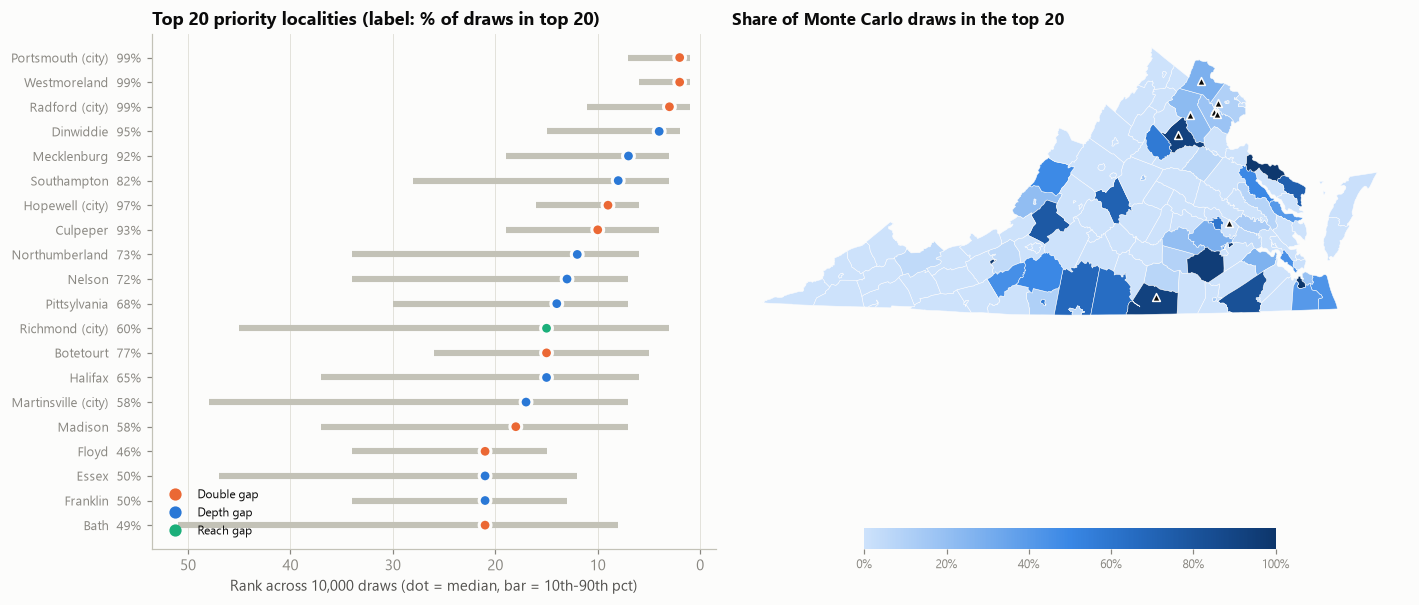

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.6), gridspec_kw={'width_ratios': [1, 1.2]})
ax = axes[0]
top = P.head(20).iloc[::-1]
y = np.arange(len(top))
ax.hlines(y, top.rank_p10, top.rank_p90, color=GRAY, lw=4)
ax.scatter(top.median_rank, y, color=[QCOL[t] for t in top.typology], s=60, zorder=3, edgecolor=SURF, linewidth=2)
ax.set_yticks(y, [f"{n.replace(' County', '').replace(' city', ' (city)')}  {f:.0%}" for n, f in zip(top.name, top.top20_freq)], fontsize=8.5)
ax.invert_xaxis(); ax.set_xlabel('Rank across 100,000 draws (dot = median, bar = 10th-90th pct)')
ax.set_title('Top 20 priority localities (label: % of draws in top 20)'); ax.grid(axis='y', visible=False)
ax.legend(handles=[Line2D([], [], marker='o', ls='', ms=7, color=QCOL[q], label=q) for q in ['Double gap', 'Depth gap', 'Reach gap']], loc='lower left', fontsize=8)
ax = axes[1]
G = geo.merge(C.reset_index(), on='FIP', how='left')
vmap(ax, 'top20_freq', cmap_blue, 'Share of Monte Carlo draws in the top 20', mpl.ticker.PercentFormatter(1, 0), 0, 1)
mark_dc(ax); ax.set_anchor('N')
plt.tight_layout(); save(fig, '06_priority_montecarlo')

## 8. Sizing the response
Three levers, matched to the typology and funded from a small, dedicated slice of the data-center electricity tax:

1. **Auto-enrollment (reach):** VDSS already verifies SNAP income in every locality. A SNAP→EAP/PIPP data match (as New York and Austin Energy do) enrolls households without a new application.
2. **Weatherization + heat pumps (depth):** target low-income oil/propane-heated homes and mobile homes in priority localities — directly operationalizing **HB2 (2026)**, which requires Dominion and APCo to reach 30% of low-income oil/propane households by 2031.
3. **Fill the remaining gap:** fund bill relief where burden stays above 6% after 1 and 2.

In [16]:
# Lever 1: auto-enrollment pool
pool = C.snap_not_in_eap.sum()
pool_rg = C.loc[C.typology.isin(['Reach gap', 'Double gap']), 'snap_not_in_eap'].sum()
avg_eap_benefit = eap_state.loc[2025, ('TOTAL $ AMOUNT PAID', 'FU')] / eap_state.loc[2025, ('TOTAL # OF HH PAID', 'FU')]
print(f'SNAP households not receiving EAP heating aid: {pool:,.0f} (in reach/double-gap localities: {pool_rg:,.0f})')
print(f'Avg EAP heating benefit FFY2025: ${avg_eap_benefit:,.0f} -> cost to serve half the pool at that benefit: '
      f'${0.5*pool*avg_eap_benefit/1e6:,.0f}M/yr')

# Lever 2: oil/propane & mobile-home households in priority localities; savings implied by LEAD itself
pri = C.index[(C.top20_freq >= 0.5) | C.typology.isin(['Depth gap', 'Double gap'])]
tgt = L[L.LI & L.FIP.isin(pri) & (L.hfl.isin(['FUEL OIL', 'BOTTLED GAS']) | L.bld.eq('MOBILE_TRAILER'))]
n_tgt = tgt.UNITS.sum()
same = L[L.LI & L.FIP.isin(pri)]
cost_oil = agg_burden(same[same.hfl.isin(['FUEL OIL', 'BOTTLED GAS'])]).avg_energy_cost
cost_el = agg_burden(same[same.hfl.eq('ELECTRICITY') & ~same.bld.eq('MOBILE_TRAILER')]).avg_energy_cost
print(f'Low-income oil/propane-heated or mobile homes in priority localities: {n_tgt:,.0f}')
print(f'LEAD-implied annual cost: oil/propane-heated ${cost_oil:,.0f} vs electric-heated (non-mobile) ${cost_el:,.0f} '
      f'-> ~${cost_oil-cost_el:,.0f}/yr difference (ACEEE estimates up to $1,400/winter from heat pump + weatherization)')
n_per_year = n_tgt / 5
print(f'Weatherize/heat-pump 1/5 of them per year at ${WX_COST:,}/home: ${n_per_year*WX_COST/1e6:,.0f}M/yr '
      f'(= {n_per_year*WX_COST/DC_TAX:.0%} of the data-center tax)')

# Lever 3: residual gap in priority localities under the 2040-high scenario
gap_pri = C.loc[pri, 'gap40h'].sum()
print(f'2040-high affordability gap in priority localities: ${gap_pri/1e6:,.0f}M/yr '
      f'({len(pri)} localities, {C.loc[pri, "li_hh"].sum():,.0f} LI households)')
print(f'Entire data-center-driven increase in the statewide gap by 2040: ${gap40l-gap26:,.0f}M-${gap40h-gap26:,.0f}M/yr')

SNAP households not receiving EAP heating aid: 276,934 (in reach/double-gap localities: 208,841)
Avg EAP heating benefit FFY2025: $415 -> cost to serve half the pool at that benefit: $58M/yr
Low-income oil/propane-heated or mobile homes in priority localities: 40,021
LEAD-implied annual cost: oil/propane-heated $4,588 vs electric-heated (non-mobile) $2,585 -> ~$2,004/yr difference (ACEEE estimates up to $1,400/winter from heat pump + weatherization)
Weatherize/heat-pump 1/5 of them per year at $8,000/home: $64M/yr (= 11% of the data-center tax)
2040-high affordability gap in priority localities: $342M/yr (68 localities, 138,130 LI households)
Entire data-center-driven increase in the statewide gap by 2040: $77M-$205M/yr


## 9. Interactive scenario map (for the expo monitor)
Slider switches between 2026 and the two 2040 data-center scenarios; hover shows each locality's burden, gap, reach, typology, and Monte Carlo priority.

In [17]:
import plotly.graph_objects as go, json
g4326 = geo.to_crs(4326).merge(C.reset_index(), on='FIP')
gj = json.loads(g4326[['FIP', 'geometry']].to_json())
for f_ in gj['features']: f_['id'] = f_['properties']['FIP']
burden = {}
for name, a in list(SCEN.items())[1:]:
    c, i = scenario_costs(a)
    d = L.assign(c=c, i=i)[L.LI]
    burden[name] = d.groupby('FIP').apply(lambda g: (g.c * g.UNITS).sum() / (g.i.clip(lower=0) * g.UNITS).sum())
cs = [[k / (len(BLUE_RAMP) - 1), col] for k, col in enumerate(BLUE_RAMP)]
def hover(name):
    b = burden[name].reindex(g4326.FIP).values
    return [f"<b>{r['name']}</b><br>Low-income energy burden: {bb:.1%}<br>Gap per LI household (2026): ${r.gap_per_li:,.0f}/yr"
            f"<br>EAP reach: {r.eap_reach:.0%}<br>SNAP HH not in EAP: {r.snap_not_in_eap:,.0f}<br>Typology: {r.typology}"
            f"<br>Top-20 priority in {r.top20_freq:.0%} of draws" for (_, r), bb in zip(g4326.iterrows(), b)]
names = list(burden)
fig = go.Figure()
for k, name in enumerate(names):
    fig.add_trace(go.Choropleth(geojson=gj, locations=g4326.FIP, z=burden[name].reindex(g4326.FIP), zmin=0.08, zmax=0.24,
                                colorscale=cs, marker_line_color='white', marker_line_width=0.4, visible=(k == 0),
                                text=hover(name), hoverinfo='text', colorbar=dict(title='LI burden', tickformat='.0%')))
steps = [dict(method='update', label=n, args=[{'visible': [j == k for j in range(len(names))]},
              {'title': f'Low-income (≤150% FPL) home energy burden — {n}'}]) for k, n in enumerate(names)]
fig.update_layout(title=f'Low-income (≤150% FPL) home energy burden — {names[0]}', sliders=[dict(active=0, steps=steps, pad={'t': 30})],
                  geo=dict(fitbounds='locations', visible=False), margin=dict(l=0, r=0, t=50, b=0), height=560,
                  paper_bgcolor=SURF, font=dict(family='Segoe UI, system-ui, sans-serif', color=INK))
fig.write_html(OUT / 'interactive_burden_map.html', include_plotlyjs=True)
print('Saved', OUT / 'interactive_burden_map.html')

Saved outputs\interactive_burden_map.html


## 10. Export & headline numbers for the write-up

In [18]:
export_cols = ['name', 'typology', 'top20_freq', 'median_rank', 'li_hh', 'li_burden26', 'li_burden40h', 'gap_per_li', 'gap26', 'gap40h',
               'dc_cost_per_li', 'eap_hh25', 'eap_reach', 'snap_hh', 'snap_xenroll', 'snap_not_in_eap', 'li_oil_propane_pct',
               'li_elec_heat_pct', 'li_mobile_pct', 'metro', 'dc_market']
C.sort_values('median_rank')[export_cols].to_csv(OUT / 'locality_priority_table.csv')
STRESS.to_csv(OUT / 'stress_test_scenarios.csv')
s26, s40 = STRESS.loc['2026 (actual prices)'], STRESS.loc['2040 high (+$37/mo)']
rur, met = cmp['Rural (nonmetro)'], cmp['Metro']
H = {
 'LI households (<=150% FPL)': f"{L.UNITS[L.LI].sum():,.0f}",
 'LI avg energy burden 2026 vs all households': f"{s26['LI avg burden']:.1%} vs {s26['All-HH avg burden']:.1%}",
 'LI burden 2040 high scenario': f"{s40['LI avg burden']:.1%}",
 'LI HH above 10% burden, 2026 -> 2040 high': f"{s26['LI HH >10%']:,.0f} -> {s40['LI HH >10%']:,.0f}",
 'Affordability gap 2026': f"${gap26:,.0f}M/yr",
 'Affordability gap 2040 (low-high)': f"${gap40l:,.0f}M-${gap40h:,.0f}M/yr",
 'Data-center-driven increase in gap': f"${gap40l-gap26:,.0f}M-${gap40h-gap26:,.0f}M/yr",
 'As share of DC electricity tax': f"{(gap40l-gap26)/(DC_TAX/1e6):.0%}-{(gap40h-gap26)/(DC_TAX/1e6):.0%}",
 'EAP payments FFY2025 / share of 2026 gap': f"${eap25:,.0f}M / {eap25/gap26:.0%}",
 'Statewide EAP reach (FPL-based)': f"{C.eap_hh25.sum()/C.eap_elig.sum():.0%}",
 'SNAP cross-enrollment / SNAP HH not in EAP': f"{C.eap_hh25.sum()/C.snap_hh.sum():.0%} / {pool:,.0f}",
 'Rural vs metro: gap per LI HH': f"${rur['gap per LI HH ($/yr)']:,.0f} vs ${met['gap per LI HH ($/yr)']:,.0f}",
 'Rural vs metro: EAP reach': f"{rur['EAP reach']:.0%} vs {met['EAP reach']:.0%}",
 'DC markets EAP reach': f"{cmp.loc['EAP reach', 'Data-center markets']:.0%}",
 'Oil/propane-heated LI burden': f"{by_fuel.loc[['FUEL OIL','BOTTLED GAS']].energy_burden.min():.0%}-{by_fuel.loc[['FUEL OIL','BOTTLED GAS']].energy_burden.max():.0%}",
 'Robust priority localities (>=80% top-20)': ', '.join(robust.name.str.replace(' County', '').str.replace(' city', ' (city)')),
 'Likely priority localities (50-80% top-20)': ', '.join(likely.name.str.replace(' County', '').str.replace(' city', ' (city)')),
 'Top-20 typology mix': ', '.join(f'{k}: {v}' for k, v in P.head(20).typology.value_counts().items()),
 'Typology counts': ', '.join(f'{k}: {v}' for k, v in C.typology.value_counts().items()),
 'Weatherization targets in priority localities': f"{n_tgt:,.0f} homes; ${n_per_year*WX_COST/1e6:,.0f}M/yr over 5 yrs",
}
for k, v in H.items(): print(f'{k:<48} {v}')
pd.Series(H).to_csv(OUT / 'headline_numbers.csv', header=['value'])

LI households (<=150% FPL)                       466,049
LI avg energy burden 2026 vs all households      14.3% vs 2.1%
LI burden 2040 high scenario                     16.7%
LI HH above 10% burden, 2026 -> 2040 high        314,224 -> 358,430
Affordability gap 2026                           $749M/yr
Affordability gap 2040 (low-high)                $826M-$955M/yr
Data-center-driven increase in gap               $77M-$205M/yr
As share of DC electricity tax                   13%-34%
EAP payments FFY2025 / share of 2026 gap         $82M / 11%
Statewide EAP reach (FPL-based)                  28%
SNAP cross-enrollment / SNAP HH not in EAP       28% / 276,934
Rural vs metro: gap per LI HH                    $1,947 vs $1,510
Rural vs metro: EAP reach                        49% vs 22%
DC markets EAP reach                             14%
Oil/propane-heated LI burden                     21%-26%
Robust priority localities (>=80% top-20)        Portsmouth (city), Westmoreland, Radford (city), Dinwi

## Limitations
* LEAD is built from ACS 2018–2022 microdata; we update prices to 2026 (EIA) and incomes with Virginia median-income growth, which likely **understates** low-income burden (low incomes grew more slowly).
* JLARC's scenarios are Dominion-specific (65% of VA residential customers, present in 104 of 133 localities); applying them statewide assumes other PJM utilities see comparable capacity-driven increases (capacity prices rose from ~$29 to ~$330/MW-day for all PJM zones).
* Household counts above a threshold use LEAD cell averages; the affordability gap is the more robust measure.
* EAP reach uses heating (fuel) households; some households receive cooling/crisis only. Small cells are suppressed by VDSS. SNAP's income limit (200% FPL under broad-based categorical eligibility) differs from EAP's (130% FPL), so "SNAP households not in EAP" is an outreach pool, not an exact eligible count.
* Data-center localities are flagged from JLARC's market list, not facility-level load data.